# Pandas Practice: The Iris Dataset

In this notebook you will independently apply everything from `01_Introduction_to_Pandas.ipynb` and `03_Introduction_to_Visualization.ipynb` to a new dataset. The **Iris dataset** is one of the most widely used datasets in data science, it contains measurements (in centimetres) of 150 iris flowers across three species. Your goal is to load it, explore it, answer questions with code, and visualise your findings.

---

![Iris species](../assets/iris.png)

---

In [1]:
# --- Starter code: run this cell first ---
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Part 1: Exploring the Data

### Challenge 1: Preview and inspect

Display the first 5 rows and the last 10 rows of the DataFrame.

In [2]:
# First 5 rows
display(df.head())

# Last 10 rows
df.tail(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


,sepal_length,sepal_width,petal_length,petal_width,species
140,6.7,3.1,5.6,2.4,Iris-virginica
141,6.9,3.1,5.1,2.3,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica
143,6.8,3.2,5.9,2.3,Iris-virginica
144,6.7,3.3,5.7,2.5,Iris-virginica
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


### Challenge 2: How many irises are in the dataset?

How many rows and columns does the DataFrame have?

In [3]:
# (rows, columns)
df.shape

(150, 5)

### Challenge 3: How many species are there?

Find out how many distinct species exist in the dataset, and what they are called.

In [4]:
print("Number of species:", df["species"].nunique())
print("Names:", df["species"].unique().tolist())

Number of species: 3
Names: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


---

## Part 2: Statistics

### Challenge 4: Descriptive statistics for petal length

Calculate the mean, median, and mode for `petal_length`. What can you conclude about the distribution?

In [5]:
pl = df["petal_length"]
print("Mean:  ", round(pl.mean(), 3))
print("Median:", pl.median())
# mode() can return several values, so it gives back a Series
print("Mode:  ", pl.mode().tolist())

Mean:   3.759
Median: 4.35
Mode:   [1.5]


**My answer:** mean 3.76, median 4.35, mode 1.5. The three "centres" disagree a lot.
The mean sits below the median, and the most common value (1.5) is far from both.
That hints at a lumpy distribution with two groups (small and large petals), not one bell curve.
The histogram in Challenge 14 confirms it.

### Challenge 5: Range and spread

What is the smallest and largest value for `petal_length`? Calculate the variance and standard deviation.

In [6]:
print("Min:     ", pl.min())
print("Max:     ", pl.max())
print("Variance:", round(pl.var(), 3))
print("Std dev: ", round(pl.std(), 3))

Min:      1.0
Max:      6.9
Variance: 3.113
Std dev:  1.764


### Challenge 6: Full summary

Use a single command to get the basic descriptive statistics for all columns.

In [7]:
# One command, all numeric columns
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Challenge 7: Overall average sepal length

What is the average `sepal_length` across all 150 flowers?

In [8]:
df["sepal_length"].mean()

np.float64(5.843333333333334)

---

## Part 3: Groupby

### Challenge 8: Count by species

Use `groupby` to count the number of observations for each species.

In [9]:
# 50 flowers per species
df.groupby("species").count()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
Iris-setosa,50,50,50,50
Iris-versicolor,50,50,50,50
Iris-virginica,50,50,50,50


### Challenge 9: Average measurements by species

Use `groupby` to find the average `sepal_length`, `sepal_width`, `petal_length`, and `petal_width` for each species.

In [10]:
df.groupby("species")[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
].mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


---

## Part 4: Column Operations and Filtering

### Challenge 10: Add a new column

Create a new column `sepal_total` that is the sum of `sepal_width` and `sepal_length`.

In [11]:
df["sepal_total"] = df["sepal_width"] + df["sepal_length"]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species,sepal_total
0,5.1,3.5,1.4,0.2,Iris-setosa,8.6
1,4.9,3.0,1.4,0.2,Iris-setosa,7.9
2,4.7,3.2,1.3,0.2,Iris-setosa,7.9
3,4.6,3.1,1.5,0.2,Iris-setosa,7.7
4,5.0,3.6,1.4,0.2,Iris-setosa,8.6


### Challenge 11: Add petal area

Create a new column `petal_area` as a rough estimate of petal area: `petal_length × petal_width`.

In [12]:
# Rough area: treat the petal as a rectangle
df["petal_area"] = df["petal_length"] * df["petal_width"]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species,sepal_total,petal_area
0,5.1,3.5,1.4,0.2,Iris-setosa,8.6,0.28
1,4.9,3.0,1.4,0.2,Iris-setosa,7.9,0.28
2,4.7,3.2,1.3,0.2,Iris-setosa,7.9,0.26
3,4.6,3.1,1.5,0.2,Iris-setosa,7.7,0.30
4,5.0,3.6,1.4,0.2,Iris-setosa,8.6,0.28


### Challenge 12: Filter by petal area

Create a new DataFrame containing only the flowers where `petal_area` is greater than 1 cm².

In [13]:
big_petals = df[df["petal_area"] > 1]
print("Flowers with petal area > 1 cm²:", len(big_petals))
print(big_petals["species"].value_counts())

Flowers with petal area > 1 cm²: 100
species
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


**Note:** exactly the 100 versicolor and virginica flowers pass. Every setosa has a petal area below 1 cm²
(its largest is 0.96), so this one rule separates setosa from the other two species.

### Challenge 13: Split by species

Create three separate DataFrames, one for each species, using the full dataset.

In [14]:
setosa_df = df[df["species"] == "Iris-setosa"]
versicolor_df = df[df["species"] == "Iris-versicolor"]
virginica_df = df[df["species"] == "Iris-virginica"]
print(len(setosa_df), len(versicolor_df), len(virginica_df))

50 50 50


---

## Part 5: Visualisation

### Challenge 14: Histogram of petal length

Create a histogram of `petal_length`. Describe the distribution, is it symmetric, skewed, or does it appear to have multiple peaks?

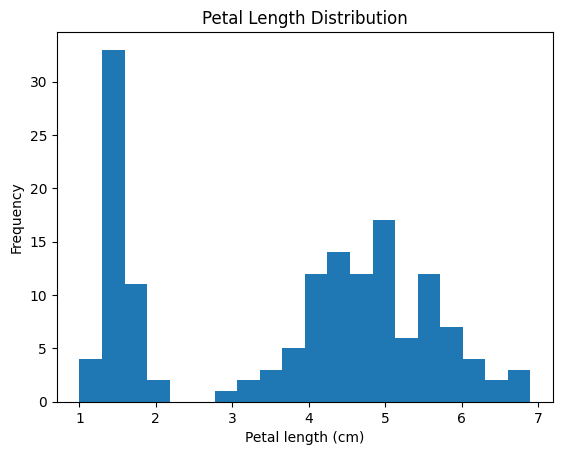

In [15]:
df["petal_length"].plot(kind="hist", bins=20,
                        title="Petal Length Distribution")
plt.xlabel("Petal length (cm)")
plt.show()

**My answer:** not symmetric and not one peak. There are two groups: a tall narrow peak between
1 and 2 cm (setosa) and a wide hump from 3 to 7 cm (versicolor and virginica). Nothing lies between
about 1.9 and 3.0 cm. This explains why mean, median and mode disagreed in Challenge 4.

### Challenge 15: Scatter matrix of petal dimensions

Create a scatter plot of `petal_length` vs `petal_width`. Do larger petals tend to be longer as well?

> Bonus: use `pd.plotting.scatter_matrix(df)` to see all pairwise relationships at once.

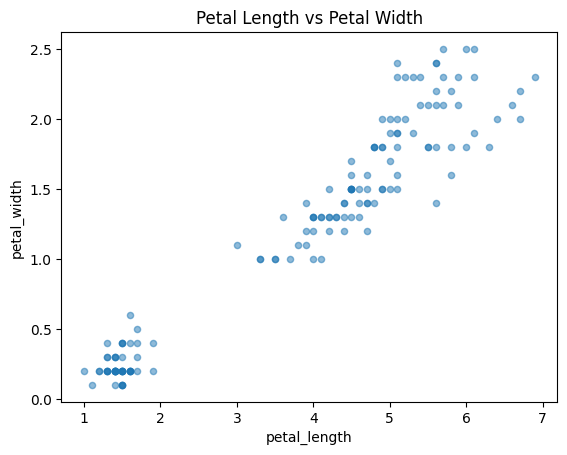

Correlation: 0.963


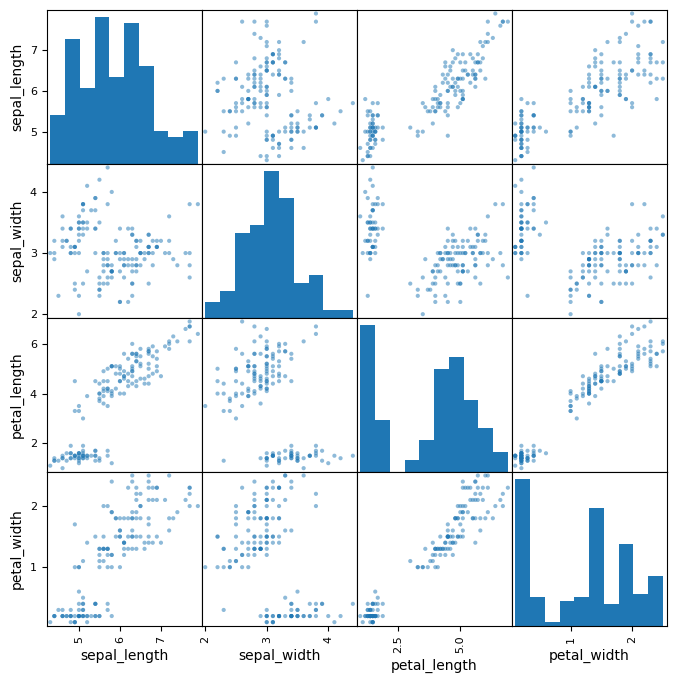

In [16]:
df.plot(kind="scatter", x="petal_length", y="petal_width",
        alpha=0.5, title="Petal Length vs Petal Width")
plt.show()
print("Correlation:", round(df["petal_length"].corr(df["petal_width"]), 3))

# Bonus: every numeric column against every other one
pd.plotting.scatter_matrix(
    df[["sepal_length", "sepal_width", "petal_length", "petal_width"]],
    figsize=(8, 8), alpha=0.5,
)
plt.show()

**My answer:** yes. Longer petals are also wider; the points form a tight rising band
(correlation 0.96, very strong).